## Example

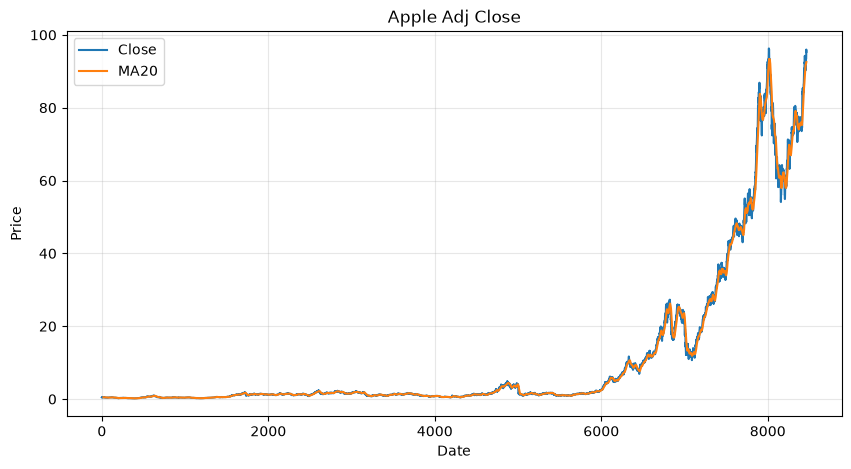

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

a = pd.read_csv(
    r'D:\quant_learning\data\pandas_exercises\09_Time_Series\Apple_Stock\appl_1980_2014.csv',
    parse_dates=['Date']
)
a = a.sort_values('Date').reset_index(drop=True)
close = a['Adj Close']
ret_log = np.log(close/close.shift(1))
fig, ax = plt.subplots(figsize=(10,5))
ax.plot(close, label='Close')
ax.plot(close.rolling(20).mean(), label='MA20')
ax.set_title('Apple Adj Close')
ax.set_xlabel('Date')
ax.set_ylabel('Price')
ax.legend()
ax.grid(alpha=0.3)



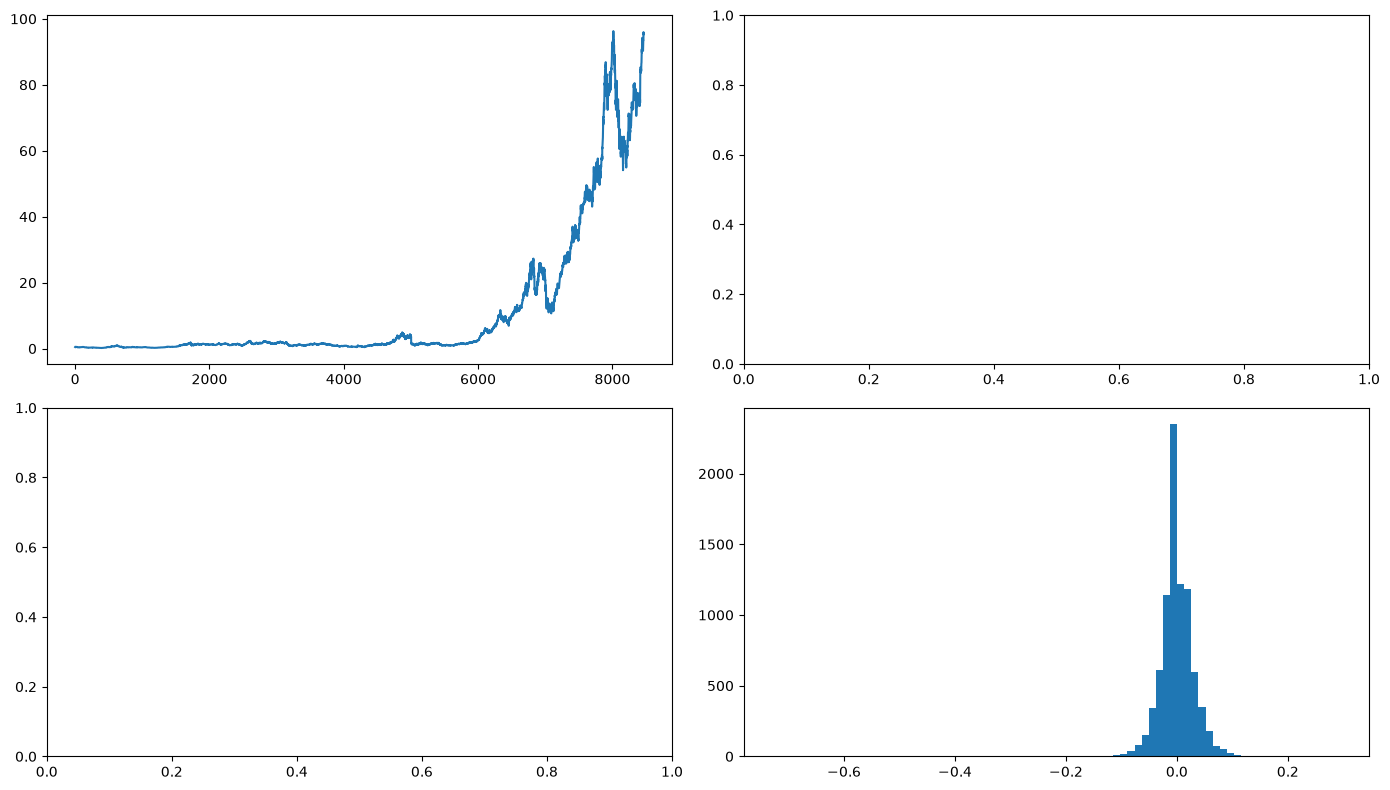

In [2]:

fig, axes = plt.subplots(2,2,figsize=(14,8),sharex=False)
axes[0,0].plot(close)
axes[1,1].hist(ret_log.dropna(),bins=80)
plt.tight_layout()

ax2 = ax.twinx()
ax2.bar(a.index, a['Volume']/1e6,alpha=0.3,color='gray')

ax.axhline(0,color='black',lw=0.8)
ax.axvline(pd.Timestamp('2008-09-15'),color='red',ls='--')

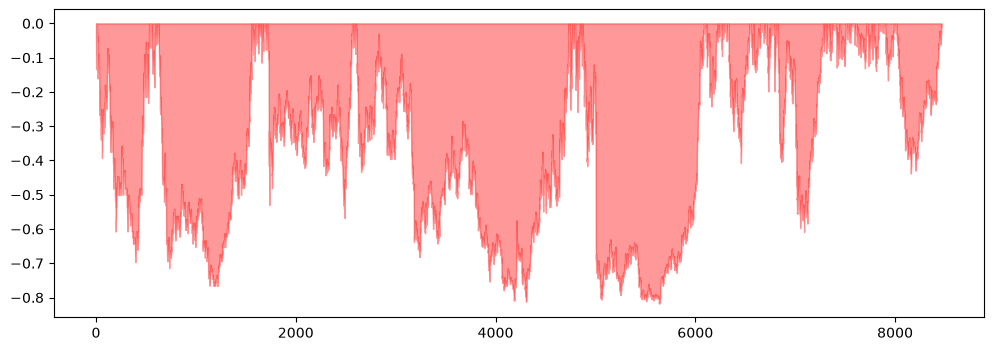

In [7]:
nav = np.exp(ret_log.fillna(0).cumsum())
drawdown = nav/nav.cummax() - 1
fig, ax = plt.subplots(figsize=(12,4))
ax.fill_between(drawdown.index, drawdown, 0, color='red',alpha=0.4)

## Exercise

In [ ]:

a = pd.read_csv(
    r'D:\quant_learning\data\pandas_exercises\09_Time_Series\Apple_Stock\appl_1980_2014.csv',
    parse_dates=['Date']
)
a = a.sort_values('Date').reset_index(drop=True)
close = a['Adj Close']
ret_simple = close.pct_change()
ret_log = np.log(close/close.shift(1))
ma5 = close.rolling(5).mean()
ma20 = close.rolling(20).mean()
vol20 = ret_log.rolling(20).std()*np.sqrt(252)
hi20 = close.rolling(20).max()
lo20 = close.rolling(20).min()
nav = np.exp(ret_log.fillna(0).cumsum())


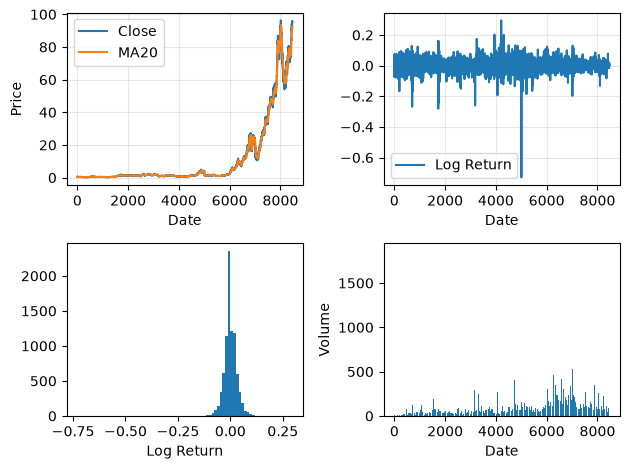

In [5]:
fig, axes = plt.subplots(2,2,sharex=False)

ax = axes[0,0]
ax.plot(close,label='Close')
ax.plot(ma20,label='MA20')
ax.set_xlabel('Date')
ax.set_ylabel('Price')
ax.legend()
ax.grid(alpha=0.3)

ax = axes[0,1]
ax.plot(ret_log,label='Log Return')
ax.set_xlabel('Date')
ax.legend()
ax.grid(alpha=0.3)

ax = axes[1,0]
ax.hist(ret_log.dropna(),bins=80)
ax.set_xlabel('Log Return')

ax = axes[1,1]
ax.bar(a.index,a['Volume']/1e6)
ax.set_ylabel('Volume')
ax.set_xlabel('Date')
plt.tight_layout()


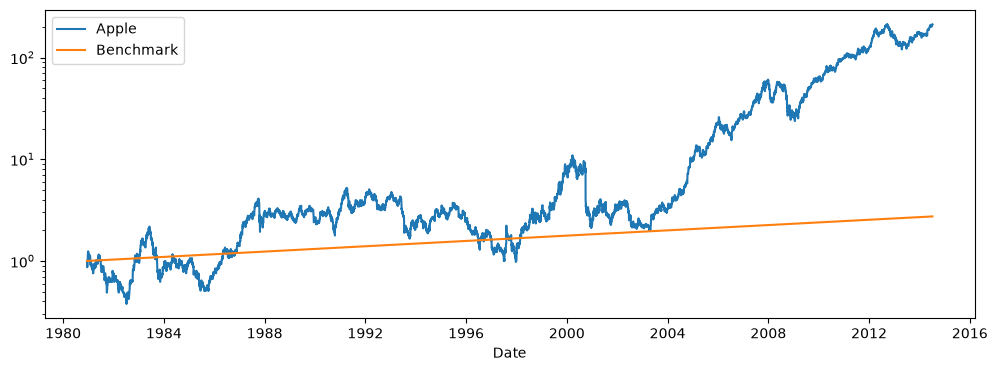

In [18]:
fig, ax = plt.subplots(figsize=(12,4))
ax.plot(a['Date'],nav,label='Apple')
ax.plot(a['Date'],np.exp(0.03*np.arange(len(nav))/252),label='Benchmark')
ax.set_yscale('log')
ax.legend()
ax.set_xlabel('Date')
fig.savefig(r'D:\quant_learning\week3_pandas_advanced\outputs\Apple_nav.png',
            dpi=150,bbox_inches='tight')


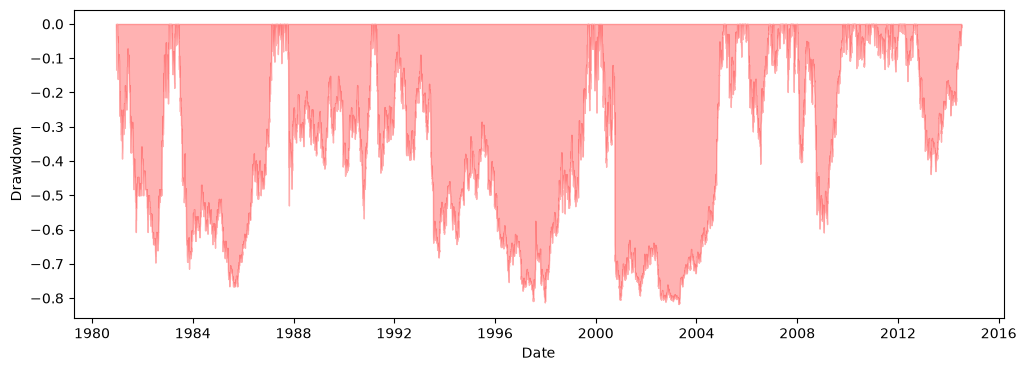

In [19]:
fig, ax = plt.subplots(figsize=(12,4))
drawdown = nav/nav.cummax()-1
ax.fill_between(a['Date'], drawdown, 0, color='red', alpha=0.3)
ax.set_xlabel('Date')
ax.set_ylabel('Drawdown')
fig.savefig(r'D:\quant_learning\week3_pandas_advanced\outputs\Apple_Drawdown.png',
            dpi=150,bbox_inches='tight')
